<a href="https://colab.research.google.com/github/hbhoomikacs24-stack/lab-programs-for-AI/blob/main/week8_1BM24CS107_forward_chaining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- Enter Fact Configuration ---
Enter American Citizen Name (e.g., Robert): Robert
Enter Weapon Identifier (e.g., T1): T1
Enter Enemy Nation Name (e.g., A): A


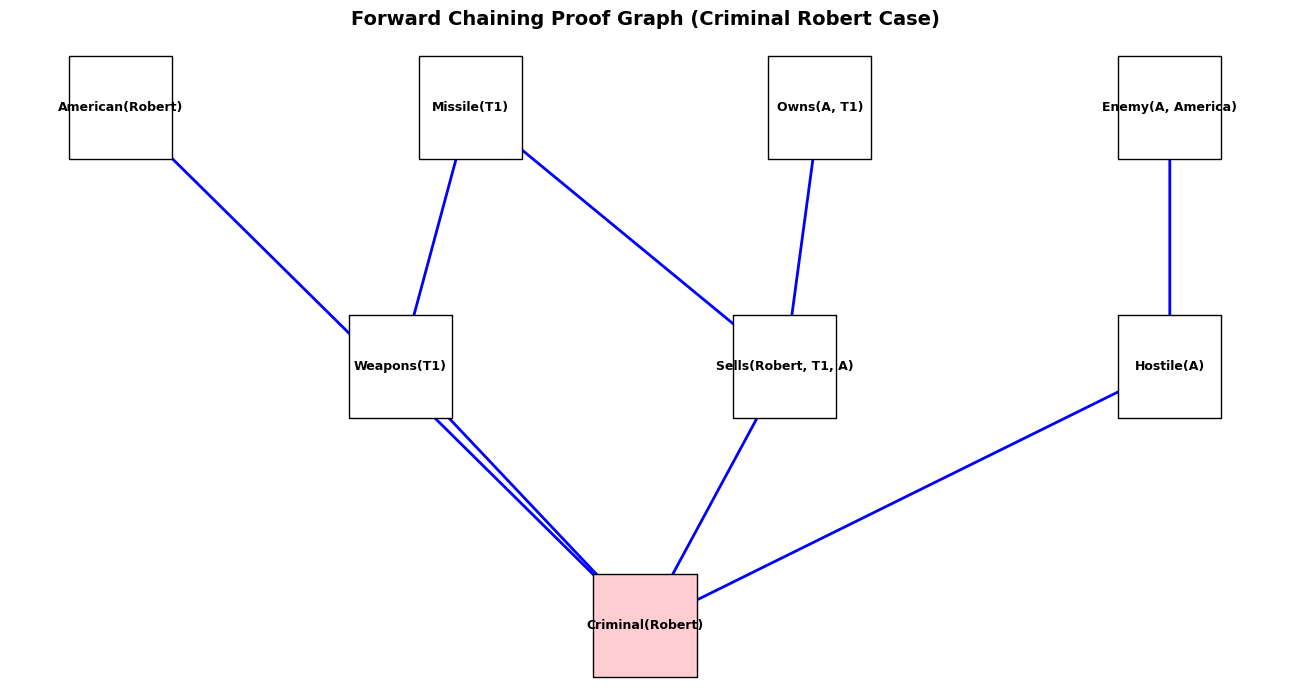

In [5]:
import matplotlib.pyplot as plt
import networkx as nx

class Fact:
    def __init__(self, predicate, arguments):
        self.predicate = predicate
        self.arguments = tuple(arguments)

    def __repr__(self):
        return f"{self.predicate}({', '.join(self.arguments)})"

    def __eq__(self, other):
        return isinstance(other, Fact) and self.predicate == other.predicate and self.arguments == other.arguments

    def __hash__(self):
        return hash((self.predicate, self.arguments))


class Rule:
    def __init__(self, antecedents, consequent):
        self.antecedents = antecedents
        self.consequent = consequent


def unify(rule_args, fact_args, theta):
    if theta is None: return None
    if len(rule_args) != len(fact_args): return None

    new_theta = theta.copy()
    for r_arg, f_arg in zip(rule_args, fact_args):
        if r_arg.islower():
            if r_arg in new_theta:
                if new_theta[r_arg] != f_arg: return None
            else:
                new_theta[r_arg] = f_arg
        else:
            if r_arg != f_arg: return None
    return new_theta


def substitute(theta, element):
    pred, args = element
    new_args = tuple(theta.get(arg, arg) for arg in args)
    return Fact(pred, new_args)


def fol_fc_ask_with_graph(KB_rules, KB_facts, alpha):
    known_facts = set(KB_facts)
    edges = []

    while True:
        new_facts_this_iteration = set()

        for rule in KB_rules:
            substitutions = [{'theta': {}, 'matched': []}]

            for ant_pred, ant_args in rule.antecedents:
                next_substitutions = []
                for sub_dict in substitutions:
                    current_theta = sub_dict['theta']
                    current_matched = sub_dict['matched']

                    for fact in known_facts:
                        if fact.predicate == ant_pred:
                            new_theta = unify(ant_args, fact.arguments, current_theta)
                            if new_theta is not None:
                                next_substitutions.append({
                                    'theta': new_theta,
                                    'matched': current_matched + [str(fact)]
                                })
                substitutions = next_substitutions

            for sub_dict in substitutions:
                theta = sub_dict['theta']
                matched_facts = sub_dict['matched']
                q_prime = substitute(theta, rule.consequent)

                if q_prime not in known_facts and q_prime not in new_facts_this_iteration:
                    new_facts_this_iteration.add(q_prime)

                    # Track an arrow connection from every active prerequisite
                    for src in matched_facts:
                        edges.append((src, str(q_prime)))

                    if q_prime == alpha:
                        known_facts.update(new_facts_this_iteration)
                        return edges

        if not new_facts_this_iteration:
            break
        known_facts.update(new_facts_this_iteration)
    return edges


# ====================================================
# CAPTURING DYNAMIC USER INPUT FOR THE CRIMINAL CASE
# ====================================================
print("--- Enter Fact Configuration ---")
person = input("Enter American Citizen Name (e.g., Robert): ").strip() or "Robert"
item = input("Enter Weapon Identifier (e.g., T1): ").strip() or "T1"
nation = input("Enter Enemy Nation Name (e.g., A): ").strip() or "A"

# Formulating Rules to match Slide 5 & 6
rules = [
    Rule([("Missile", ("x",))], ("Weapons", ("x",))),
    Rule([("Enemy", ("x", "America"))], ("Hostile", ("x",))),
    Rule([("Missile", ("x",)), ("Owns", (nation, "x"))], ("Sells", (person, "x", nation))),
    Rule([("American", ("p",)), ("Weapons", ("q",)), ("Sells", ("p", "q", "r")), ("Hostile", ("r",))], ("Criminal", ("p",)))
]

# Formulating Initial ground facts
initial_facts = [
    Fact("American", (person,)),
    Fact("Missile", (item,)),
    Fact("Owns", (nation, item)),
    Fact("Enemy", (nation, "America"))
]

goal = Fact("Criminal", (person,))

# Run tracking loop
graph_edges = fol_fc_ask_with_graph(rules, initial_facts, goal)

# Explicitly ensure an edge is visible directly from American baseline node to Criminal target node
graph_edges.append((f"American({person})", f"Criminal({person})"))

# ====================================================
# DRAWING COMPONENT
# ====================================================
plt.figure(figsize=(13, 7))
G = nx.DiGraph()

# Add all components
all_nodes = [
    f'American({person})', f'Missile({item})', f'Owns({nation}, {item})', f'Enemy({nation}, America)',
    f'Weapons({item})', f'Sells({person}, {item}, {nation})', f'Hostile({nation})', f'Criminal({person})'
]
G.add_nodes_from(all_nodes)
G.add_edges_from(graph_edges)

# Manual locked coordinates to perfectly match your slide visual style
pos = {
    f'American({person})': (1.0, 3.0),
    f'Missile({item})': (2.0, 3.0),
    f'Owns({nation}, {item})': (3.0, 3.0),
    f'Enemy({nation}, America)': (4.0, 3.0),

    f'Weapons({item})': (1.8, 2.0),
    f'Sells({person}, {item}, {nation})': (2.9, 2.0),
    f'Hostile({nation})': (4.0, 2.0),

    f'Criminal({person})': (2.5, 1.0)
}

node_colors = []
for node in G.nodes():
    if "Criminal" in node:
        node_colors.append('#ffcdd2') # Target box highlighted
    else:
        node_colors.append('#ffffff') # Clean white boxes

nx.draw_networkx_nodes(G, pos, node_size=5500, node_color=node_colors, node_shape='s', edgecolors='black')
nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=22, edge_color='blue', width=2)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold', font_family='sans-serif')

plt.title("Forward Chaining Proof Graph (Criminal Robert Case)", fontsize=14, fontweight='bold', pad=20)
plt.axis('off')
plt.tight_layout()
plt.show()
